# Generate Fluvial Pluvial Delineations using Max WSE Arrival Time

### Fluvial vs. Pluvial Flooding

Fluvial flooding is driven by channel or river overflow. Pluvial flooding is driven by rainfall-runoff ponding or overland flow that is not directly connected to the channel flood wave.

This notebook derives a draft separation line from HEC-RAS 2D result timing. Cells that reach maximum water surface elevation at similar times are treated as part of the same hydraulic response. Sharp changes in maximum WSE arrival time across adjacent cells are used as candidate transition lines between channel-driven and rainfall-driven flooding.

The output is a draft GIS layer for flood-source interpretation. It is most useful for screening, map review, and identifying where additional hydraulic interpretation is needed before drawing a final closed boundary.

### References

- [FEMA Flood Insurance Study Guidelines](https://www.fema.gov/flood-maps/guidance-partners/guidelines-standards)
- [Urban Drainage and Flood Control District Guidelines](https://udfcd.org/criteria-manual/)
- HEC-RAS 2D Modeling User's Manual, compound flooding guidance

In [1]:
# =============================================================================
# DEVELOPMENT MODE TOGGLE
# =============================================================================
USE_LOCAL_SOURCE = False  # <-- TOGGLE THIS

if USE_LOCAL_SOURCE:
    import sys
    from pathlib import Path
    local_path = str(Path.cwd().parent)
    if local_path not in sys.path:
        sys.path.insert(0, local_path)
    print(f"📁 LOCAL SOURCE MODE: Loading from {local_path}/ras_commander")
else:
    print("📦 PIP PACKAGE MODE: Loading installed ras-commander")

# Import ras-commander
from ras_commander import HdfBase, HdfFluvialPluvial, HdfMesh, HdfResultsMesh, HdfResultsPlot, HdfUtils, RasCmdr, RasExamples, RasPlan, init_ras_project, ras

# Verify which version loaded
import ras_commander
print(f"✓ Loaded: {ras_commander.__file__}")

📦 PIP PACKAGE MODE: Loading installed ras-commander


✓ Loaded: D:\CLB-Temp\clb-t3-pr534\repo2\ras_commander\__init__.py


## Parameters

Configure these values to customize the notebook for your project.

In [2]:
# =============================================================================
# PARAMETERS - Edit these to customize the notebook
# =============================================================================
from pathlib import Path

# Project Configuration
PROJECT_NAME = "BaldEagleCrkMulti2D"           # Example project to extract
RAS_VERSION = "7.0"               # HEC-RAS version (6.3, 6.5, 6.6, etc.)

# HDF Analysis Settings
PLAN = "06"                       # Plan number (for HDF file path)
TIME_INDEX = -1                   # Time step index (-1 = last)
PROFILE = "Max"                   # Profile name for steady analysis


## Method: Max WSE Arrival Time

HEC-RAS records the maximum water surface elevation for each 2D cell and the time when that maximum occurs. A channel-driven flood wave usually produces coherent arrival times radiating from the stream corridor. Pluvial flooding commonly peaks on a different timing pattern because it is controlled by local rainfall accumulation, drainage capacity, and overland flow paths.

This workflow compares adjacent mesh cells and flags face segments where the difference in maximum WSE arrival time exceeds the selected threshold. Those segments form a draft fluvial-pluvial separation line.

### RAS Project DataFrames

Plan, geometry, and HDF paths are read from ras-commander DataFrames such as `plan_df`, `geom_df`, and `hdf_paths_df`. Spatial elements such as mesh faces, nodes, and boundaries are handled as GeoDataFrames.

## Package Installation and Environment Setup
Uncomment and run package installation commands if needed

In [3]:
# Install ras-commander from pip (uncomment to install if needed)
#!pip install ras-commander
# This installs ras-commander and all dependencies

In [4]:
# Import all required modules
#from ras_commander import HdfBase, HdfMesh, HdfResultsMesh, HdfResultsPlot, HdfUtils, RasCmdr, RasExamples, RasPlan, init_ras_project, ras  # Import all ras-commander modules

# Import the required libraries for this notebook
import h5py
import numpy as np
import requests
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import pyproj
from shapely.geometry import Point, LineString, Polygon
import xarray as xr
from pathlib import Path

In [5]:
# Download the BaldEagleCrkMulti2D project from HEC and run plan 06

# Define the path to the BaldEagleCrkMulti2D project
import logging

# Extract project using suffix parameter (returns correct path)
bald_eagle_path = RasExamples.extract_project(PROJECT_NAME, suffix="14")

# Initialize the RAS project using the default global ras object
init_ras_project(bald_eagle_path, RAS_VERSION)
logging.info(f"Bald Eagle project initialized with folder: {ras.project_folder}")

# Use the plan number from parameters
plan_number = PLAN

# Update the run flags in the plan file
RasPlan.update_run_flags(
    plan_number,
    geometry_preprocessor=True,  # Run HTab
    unsteady_flow_simulation=True,  # Run UNet
    post_processor=True,  # Run PostProcess
    floodplain_mapping=False,  # Run RASMapper
)

# Execute Plan 06 using RasCmdr with skip_existing=True
# This will skip execution if HDF results already exist with "Complete Process"
print(f"Executing Plan {plan_number} for the Bald Eagle Creek project...")
success_bald_eagle = RasCmdr.compute_plan(plan_number, skip_existing=True)
if success_bald_eagle:
    print(f"Plan {plan_number} executed successfully (or skipped - results exist).")
else:
    print(f"Plan {plan_number} execution failed for Bald Eagle.")

2026-10-15 02:31:53 - ras_commander.RasExamples - INFO - Successfully extracted project 'BaldEagleCrkMulti2D' to example_projects\BaldEagleCrkMulti2D_14


2026-10-15 02:31:54 - ras_commander.RasPrj - WARNING - Skipping HDF results summary for plan 13 because hdf is the selected result format


2026-10-15 02:31:54 - ras_commander.RasPrj - WARNING - Skipping HDF results summary for plan 15 because hdf is the selected result format


2026-10-15 02:31:54 - ras_commander.RasPrj - WARNING - Skipping HDF results summary for plan 17 because hdf is the selected result format


2026-10-15 02:31:54 - ras_commander.RasPrj - WARNING - Skipping HDF results summary for plan 18 because hdf is the selected result format


...

2026-10-15 02:31:54 - root - INFO - Bald Eagle project initialized with folder: D:\CLB-Temp\clb-t3-pr534\repo2\examples\example_projects\BaldEagleCrkMulti2D_14


2026-10-15 02:31:54 - ras_commander.RasPlan - INFO - Updated run flags in plan file: BaldEagleDamBrk.p06 (flags modified: 4)


2026-10-15 02:31:54 - ras_commander.ExecutionArtifacts - INFO - Removed plan 06 execution artifact: BaldEagleDamBrk.bco06


Executing Plan 06 for the Bald Eagle Creek project...


Plan 06 executed successfully (or skipped - results exist).


In [6]:
# Display results summary from results_df
desired_cols = ['plan_number', 'plan_title', 'completed', 'has_errors', 'has_warnings', 'runtime_complete_process_hours']
available_cols = [c for c in desired_cols if c in ras.results_df.columns]
ras.results_df[available_cols]

,plan_number,plan_title,completed,has_errors,has_warnings,runtime_complete_process_hours
0,06,Gridded Precip - Infiltration,True,False,False,0.086176


### Optional: Use a Local Project

Use this alternate setup when you want to run the workflow against an existing HEC-RAS project instead of the extracted example project.

```python
your_project_path = Path(r"D:\yourprojectpath")

init_ras_project(your_project_path, "6.6")
plan_number = "01"
```

The selected plan must have a HEC-RAS 6.x results HDF file with maximum WSE and maximum WSE arrival-time output.

# Explore Project Dataframes using 'ras' Object

In [7]:
# Load Plan and Geometry Dataframes and find Plan and Geometry HDF Paths

# Display plan_df for bald_eagle project
print("Plan DataFrame for bald_eagle project:")
ras.plan_df

Plan DataFrame for bald_eagle project:


,plan_number,unsteady_number,geometry_number,Plan Title,Program Version,Short Identifier,Simulation Date,Computation Interval,Output Interval,Instantaneous Interval,...,num_cross_sections,mesh_cell_count,mesh_area_names,geometry_metadata_source,geometry_metadata_valid,geometry_metadata_error,geometry_type,plan_type,plan_classification_valid,plan_classification_reason
0,13,07,06,PMF with Multi 2D Areas,5.10,PMF Multi 2D,"01JAN1999,1200,04JAN1999,1200",30SEC,30MIN,1HOUR,...,192,4120,"[193, 194, LockHaven]",hdf,True,None,1D/2D,unsteady_1d_2d,True,None
1,15,12,08,1d-2D Dambreak Refined Grid,5.10,1D-2D Refined Grid,"01JAN1999,1200,04JAN1999,1200",20SEC,5MIN,1HOUR,...,89,14206,[BaldEagleCr],hdf,True,None,1D/2D,unsteady_1d_2d,True,None
2,17,09,10,2D to 1D No Dam,5.00,2D to 1D No Dam,"01JAN1999,1200,06JAN1999,1200",1MIN,1MIN,1HOUR,...,69,5330,[Upstream2D],hdf,True,None,1D/2D,unsteady_1d_2d,True,None
3,18,10,11,2D to 2D Run,5.00,2D to 2D Run,"01JAN1999,1200,04JAN1999,1200",20SEC,1MIN,1HOUR,...,0,4425,"[BaldEagleCr, Upper 2D Area]",hdf,True,None,2D,unsteady_2d,True,None
4,19,11,12,SA to 2D Dam Break Run,5.00,SA to 2D Dam Break,"01JAN1999,1200,04JAN1999,1200",20SEC,1MIN,1HOUR,...,0,3439,[BaldEagleCr],hdf,True,None,2D,unsteady_2d,True,None
5,03,13,09,Single 2D Area - Internal Dam Structure,5.04,Single 2D,"01JAN1999,1200,04JAN1999,1200",30SEC,1MIN,1HOUR,...,0,18066,[BaldEagleCr],hdf,True,None,2D,unsteady_2d,True,None
6,04,01,13,SA to 2D Area Conn - 2D Levee Structure,5.00,2D Levee Struc,"01JAN1999,1200,04JAN1999,1200",20SEC,1MIN,1HOUR,...,0,14364,[BaldEagleCr],hdf,True,None,2D,unsteady_2d,True,None
7,02,01,01,SA to Detailed 2D Breach,5.10,SA-2D Det Brch,"01JAN1999,1200,04JAN1999,1200",10SEC,1MIN,1HOUR,...,0,87039,[BaldEagleCr],hdf,True,None,2D,unsteady_2d,True,None
8,01,01,01,SA to Detailed 2D Breach FEQ,5.03,SA-2D Det FEQ,"01JAN1999,1200,04JAN1999,1200",5SEC,1MIN,1HOUR,...,0,87039,[BaldEagleCr],hdf,True,None,2D,unsteady_2d,True,None
9,05,02,03,Single 2D area with Bridges FEQ,5.10,Single 2D Bridges FEQ,"01JAN1999,1200,04JAN1999,1200",5SEC,1MIN,1HOUR,...,0,24718,[BaldEagleCr],hdf,True,None,2D,unsteady_2d,True,None


In [8]:
print("\nGeometry DataFrame for the project:")
ras.geom_df


Geometry DataFrame for the project:


,geom_file,geom_number,full_path,hdf_path,has_1d_xs,has_2d_mesh,num_cross_sections,num_inline_structures,num_bridges,num_culverts,...,num_lateral_structures,num_sa_2d_connections,mesh_cell_count,mesh_area_names,geometry_metadata_source,geometry_metadata_valid,geometry_metadata_error,geom_title,description,geometry_type
0,g06,06,D:\CLB-Temp\clb-t3-pr534\repo2\examples\exampl...,D:\CLB-Temp\clb-t3-pr534\repo2\examples\exampl...,True,True,192,9,8,0,...,11,1,4120,"[193, 194, LockHaven]",hdf,True,None,Bald Eagle Multi 2D Areas,Foster Joseph Sayers Dam and Reservoir,1D/2D
1,g08,08,D:\CLB-Temp\clb-t3-pr534\repo2\examples\exampl...,D:\CLB-Temp\clb-t3-pr534\repo2\examples\exampl...,True,True,89,2,1,0,...,2,0,14206,[BaldEagleCr],hdf,True,None,1D-2D Dam Break Model Refined Grid,Foster Joseph Sayers Dam and Reservoir,1D/2D
2,g10,10,D:\CLB-Temp\clb-t3-pr534\repo2\examples\exampl...,D:\CLB-Temp\clb-t3-pr534\repo2\examples\exampl...,True,True,69,6,6,0,...,7,0,5330,[Upstream2D],hdf,True,None,U.S 2D - D.S 1D No Dam,None,1D/2D
3,g11,11,D:\CLB-Temp\clb-t3-pr534\repo2\examples\exampl...,D:\CLB-Temp\clb-t3-pr534\repo2\examples\exampl...,False,True,0,0,0,0,...,0,1,4425,"[BaldEagleCr, Upper 2D Area]",hdf,True,None,2D to 2D Connection,None,2D
4,g12,12,D:\CLB-Temp\clb-t3-pr534\repo2\examples\exampl...,D:\CLB-Temp\clb-t3-pr534\repo2\examples\exampl...,False,True,0,0,0,0,...,0,1,3439,[BaldEagleCr],hdf,True,None,SA to 2D Connection,None,2D
5,g09,09,D:\CLB-Temp\clb-t3-pr534\repo2\examples\exampl...,D:\CLB-Temp\clb-t3-pr534\repo2\examples\exampl...,False,True,0,0,0,0,...,0,1,18066,[BaldEagleCr],hdf,True,None,Single 2D Area - Internal Dam Structure,None,2D
6,g13,13,D:\CLB-Temp\clb-t3-pr534\repo2\examples\exampl...,D:\CLB-Temp\clb-t3-pr534\repo2\examples\exampl...,False,True,0,0,0,0,...,0,4,14364,[BaldEagleCr],hdf,True,None,SA to 2D Flow Area,None,2D
7,g01,01,D:\CLB-Temp\clb-t3-pr534\repo2\examples\exampl...,D:\CLB-Temp\clb-t3-pr534\repo2\examples\exampl...,False,True,0,0,0,0,...,0,4,87039,[BaldEagleCr],hdf,True,None,SA to 2D Flow Area - Detailed,None,2D
8,g03,03,D:\CLB-Temp\clb-t3-pr534\repo2\examples\exampl...,D:\CLB-Temp\clb-t3-pr534\repo2\examples\exampl...,False,True,0,0,0,0,...,0,11,24718,[BaldEagleCr],hdf,True,None,Single 2D Area with Bridges and Breaklin,None,2D
9,g02,02,D:\CLB-Temp\clb-t3-pr534\repo2\examples\exampl...,D:\CLB-Temp\clb-t3-pr534\repo2\examples\exampl...,False,True,0,0,0,0,...,0,2,28449,[BaldEagleCr],hdf,True,None,Single 2D Area -With Infiltration,None,2D


In [9]:
print("\nUnsteady DataFrame for the project:")
ras.unsteady_df


Unsteady DataFrame for the project:


,unsteady_number,full_path,Flow Title,Program Version,Use Restart,description,Precipitation Mode,Wind Mode,Met BC=Precipitation|Mode,Met BC=Evapotranspiration|Mode,Met BC=Precipitation|Expanded View,Met BC=Precipitation|Constant Units,Met BC=Precipitation|Gridded Source
0,07,D:\CLB-Temp\clb-t3-pr534\repo2\examples\exampl...,PMF with Multi 2D Areas,5.00,0,,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,08,D:\CLB-Temp\clb-t3-pr534\repo2\examples\exampl...,PMF for Upstream 2D,4.20,0,,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,09,D:\CLB-Temp\clb-t3-pr534\repo2\examples\exampl...,Upstream 2D,5.00,0,,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,10,D:\CLB-Temp\clb-t3-pr534\repo2\examples\exampl...,1972 Flood Event - 2D to 2D Run,5.00,0,,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,11,D:\CLB-Temp\clb-t3-pr534\repo2\examples\exampl...,1972 Flood Event - SA to 2D Run,5.00,0,,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,12,D:\CLB-Temp\clb-t3-pr534\repo2\examples\exampl...,PMF for 1D - 2D,5.00,0,,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,13,D:\CLB-Temp\clb-t3-pr534\repo2\examples\exampl...,Single 2D Area,5.00,0,,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,01,D:\CLB-Temp\clb-t3-pr534\repo2\examples\exampl...,1972 Flood Event - 2D Leve Structure,5.10,0,,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,02,D:\CLB-Temp\clb-t3-pr534\repo2\examples\exampl...,Single 2D Area with Bridges,5.10,0,,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,03,D:\CLB-Temp\clb-t3-pr534\repo2\examples\exampl...,Gridded Precipitation,6.00,0,,Enable,No Wind Forces,Gridded,None,-1,mm/hr,DSS


In [10]:
print("\nBoundary Conditions DataFrame for the project:")
ras.boundaries_df 


Boundary Conditions DataFrame for the project:


,unsteady_number,boundary_condition_number,river_reach_name,river_station,storage_area_name,pump_station_name,area_2d,bc_line_name,bc_type,hydrograph_type,...,Program Version,Use Restart,description,Precipitation Mode,Wind Mode,Met BC=Precipitation|Mode,Met BC=Evapotranspiration|Mode,Met BC=Precipitation|Expanded View,Met BC=Precipitation|Constant Units,Met BC=Precipitation|Gridded Source
0,07,1,Bald Eagle Cr.,Lock Haven,137520,,,,Flow Hydrograph,Flow Hydrograph,...,5.00,0,,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,07,2,Bald Eagle Cr.,Lock Haven,81454,,,,Gate Opening,NaN,...,5.00,0,,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,07,3,Bald Eagle Cr.,Lock Haven,28519,,,,Lateral Inflow Hydrograph,Lateral Inflow Hydrograph,...,5.00,0,,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,07,4,Bald Eagle Cr.,Lock Haven,1,,,,Lateral Inflow Hydrograph,Lateral Inflow Hydrograph,...,5.00,0,,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,07,5,Bald Eagle Cr.,Lock Haven,136948,82303,,,Uniform Lateral Inflow Hydrograph,Uniform Lateral Inflow Hydrograph,...,5.00,0,,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,07,6,Bald Eagle Cr.,Lock Haven,80720,67130,,,Uniform Lateral Inflow Hydrograph,Uniform Lateral Inflow Hydrograph,...,5.00,0,,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,07,7,Bald Eagle Cr.,Lock Haven,76865,,,,Lateral Inflow Hydrograph,Lateral Inflow Hydrograph,...,5.00,0,,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,07,8,Bald Eagle Cr.,Lock Haven,67130,,,,Lateral Inflow Hydrograph,Lateral Inflow Hydrograph,...,5.00,0,,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,07,9,Bald Eagle Cr.,Lock Haven,66041,1,,,Uniform Lateral Inflow Hydrograph,Uniform Lateral Inflow Hydrograph,...,5.00,0,,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,07,10,Bald Eagle Cr.,Lock Haven,-1867,,,,Normal Depth,NaN,...,5.00,0,,NaN,NaN,NaN,NaN,NaN,NaN,NaN


# Find Paths for Results and Geometry HDF's

In [11]:
# Use the plan_number defined earlier
print(f"Using plan number: {plan_number}")

# Get the plan HDF path for the plan_number defined above
plan_hdf_path = ras.plan_df.loc[ras.plan_df['plan_number'] == plan_number, 'HDF_Results_Path'].values[0]

Using plan number: 06


In [12]:
plan_hdf_path

'D:\\CLB-Temp\\clb-t3-pr534\\repo2\\examples\\example_projects\\BaldEagleCrkMulti2D_14\\BaldEagleDamBrk.p06.hdf'

In [13]:
# Get the geometry HDF path
geom_hdf_path = ras.plan_df.loc[ras.plan_df['plan_number'] == plan_number, 'Geom Path'].values[0] + '.hdf'

In [14]:
geom_hdf_path


'D:\\CLB-Temp\\clb-t3-pr534\\repo2\\examples\\example_projects\\BaldEagleCrkMulti2D_14\\BaldEagleDamBrk.g09.hdf'

In [15]:
print(f"\nPlan HDF path for Plan {plan_number}: {plan_hdf_path}")
print(f"Geometry HDF path for Plan {plan_number}: {geom_hdf_path}")


Plan HDF path for Plan 06: D:\CLB-Temp\clb-t3-pr534\repo2\examples\example_projects\BaldEagleCrkMulti2D_14\BaldEagleDamBrk.p06.hdf
Geometry HDF path for Plan 06: D:\CLB-Temp\clb-t3-pr534\repo2\examples\example_projects\BaldEagleCrkMulti2D_14\BaldEagleDamBrk.g09.hdf


# Fluvial-Pluvial Boundary Extraction

The extraction routine reads the maximum WSE result layer and its associated maximum-WSE time stamp. Adjacent mesh faces are compared, and face segments are retained where the timing difference exceeds the selected threshold, which defaults to 12 hours.

The retained segments form a draft boundary derived directly from HEC-RAS 2D results. Adjacent segments are merged where possible to simplify the geometry, but the result is still a draft line layer. For mapping or downstream polygon processing, expect to review the linework in GIS and close gaps where the mesh-derived boundary needs interpolation.

In [16]:
# Using mesh_max_ws, get the cell coordinates and plot the max water surface as a map
import matplotlib.pyplot as plt
from ras_commander import HdfMesh
from ras_commander import HdfResultsMesh
from shapely.geometry import Point

# Get mesh max water surface
max_ws_df = HdfResultsMesh.get_mesh_max_ws(plan_hdf_path)

print("max_ws_df")
print(max_ws_df)

# If you get an error here, you may have a pre-6.0 HDF.  Re-run in 6.x to generate a new results file

max_ws_df


         mesh_name  cell_id  maximum_water_surface maximum_water_surface_time  \
0      BaldEagleCr        0             704.053711        2018-09-10 18:00:00   
1      BaldEagleCr        1             692.376953        2018-09-10 18:04:00   
2      BaldEagleCr        2             671.182983        2018-09-10 18:13:00   
3      BaldEagleCr        3             660.605042        2018-09-10 18:54:00   
4      BaldEagleCr        4             660.585876        2018-09-10 18:55:40   
...            ...      ...                    ...                        ...   
18061  BaldEagleCr    18061             550.542236        2018-09-10 19:00:00   
18062  BaldEagleCr    18062             550.562988        2018-09-10 19:00:20   
18063  BaldEagleCr    18063             550.590271        2018-09-10 19:00:00   
18064  BaldEagleCr    18064             568.098022        2018-09-10 18:00:00   
18065  BaldEagleCr    18065             551.708435        2018-09-10 09:57:00   

       is_ghost_cell       

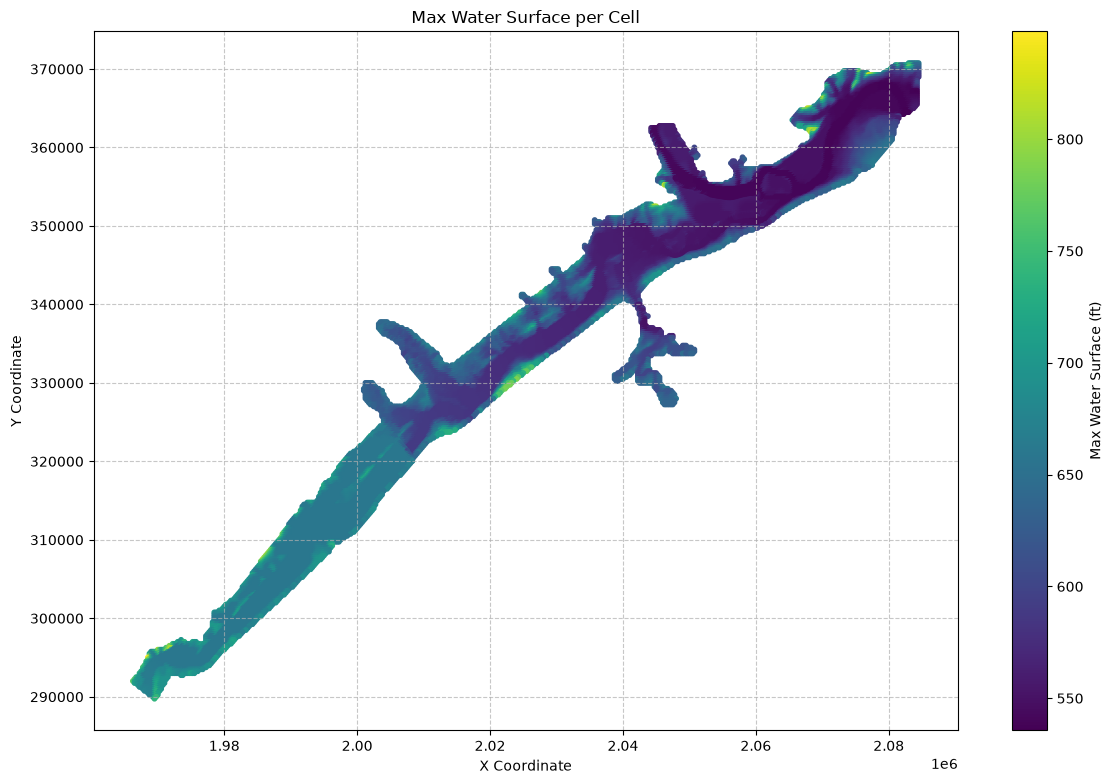

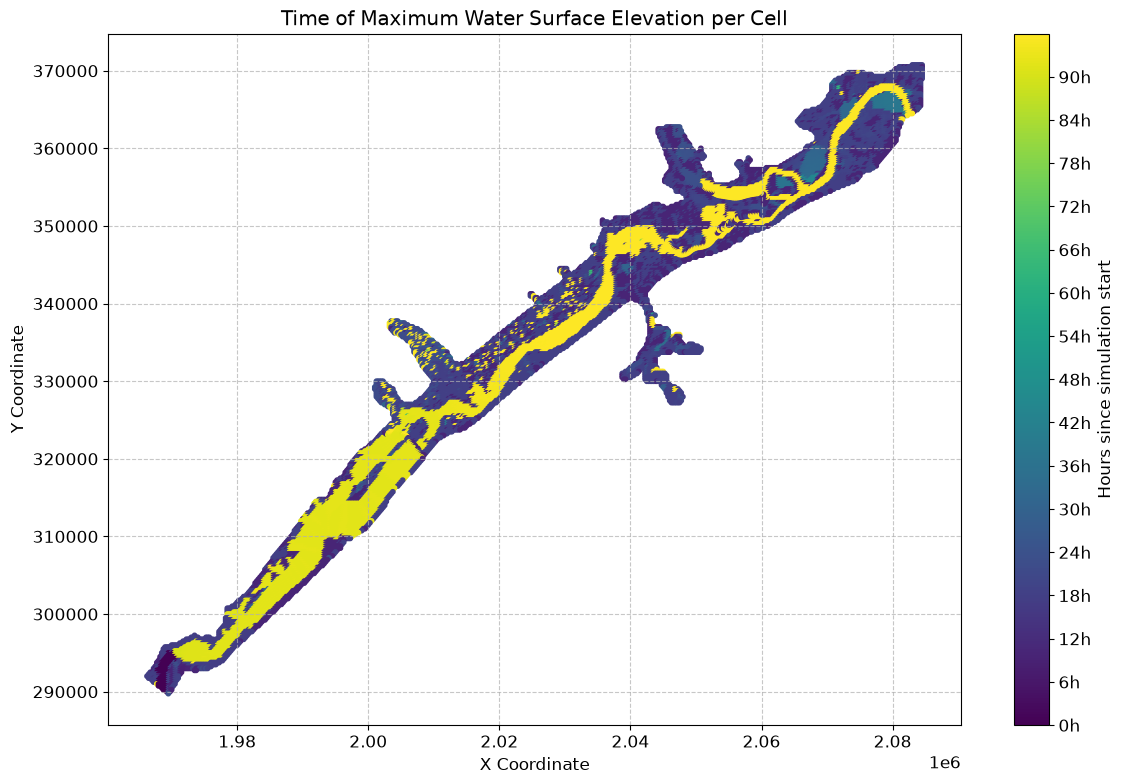


First few rows of the merged dataframe:


,mesh_name,cell_id,maximum_water_surface,maximum_water_surface_time,is_ghost_cell,geometry
0,BaldEagleCr,0,704.053711,2018-09-10 18:00:00,False,POINT (2083000 370750)
1,BaldEagleCr,1,692.376953,2018-09-10 18:04:00,False,POINT (2083250 370750)
2,BaldEagleCr,2,671.182983,2018-09-10 18:13:00,False,POINT (2083500 370750)
3,BaldEagleCr,3,660.605042,2018-09-10 18:54:00,False,POINT (2083750 370750)
4,BaldEagleCr,4,660.585876,2018-09-10 18:55:40,False,POINT (2084000 370750)
...,...,...,...,...,...,...
18061,BaldEagleCr,18061,550.542236,2018-09-10 19:00:00,False,POINT (2060527.525 351824.248)
18062,BaldEagleCr,18062,550.562988,2018-09-10 19:00:20,False,POINT (2060770.734 351834.938)
18063,BaldEagleCr,18063,550.590271,2018-09-10 19:00:00,False,POINT (2060928.42 351836.275)
18064,BaldEagleCr,18064,568.098022,2018-09-10 18:00:00,False,POINT (2061024.634 351710.661)


In [17]:
# Call the function to plot
HdfResultsPlot.plot_results_max_wsel(max_ws_df)

# Plot the time of maximum water surface elevation
HdfResultsPlot.plot_results_max_wsel_time(max_ws_df)

# Print the first few rows of the merged dataframe for verification
print("\nFirst few rows of the merged dataframe:")
max_ws_df


In [18]:
# Use HdfUtils for extracting projection
print("\nExtracting Projection from HDF")
projection = HdfBase.get_projection(hdf_path=geom_hdf_path)
if projection:
    print(f"Projection: {projection}")
else:
    print("No projection information found.")


Extracting Projection from HDF
Projection: EPSG:2271


In [19]:
# Example: Extract Cell Polygons
print("\nExample 6: Extracting Cell Polygons")
cell_polygons_gdf = HdfMesh.get_mesh_cell_polygons(geom_hdf_path)


# Call the function to plot cell polygons
#cell_polygons_gdf = HdfFluvialPluvial.plot_cell_polygons(cell_polygons_gdf, projection)



Example 6: Extracting Cell Polygons


In [20]:
import geopandas as gpd
import pandas as pd
from shapely.geometry import LineString, Polygon, MultiLineString
from collections import defaultdict
from tqdm import tqdm
from rtree import index


# Example usage:
boundary_gdf = HdfFluvialPluvial.calculate_fluvial_pluvial_boundary(plan_hdf_path, delta_t=72)

2026-10-15 02:39:25 - ras_commander.hdf.HdfFluvialPluvial - INFO - Fluvial/pluvial boundary: 3198 line(s), delta_t=72 hr.


In [21]:
# Calculate statistics about the boundary line lengths
boundary_lengths = boundary_gdf.geometry.length

print("Boundary line length statistics:")
print(f"Max length: {boundary_lengths.max():.2f}")
print(f"Min length: {boundary_lengths.min():.2f}")
print(f"Average length: {boundary_lengths.mean():.2f}")
print(f"Median length: {boundary_lengths.median():.2f}")

# Print general information about the boundary GeoDataFrame
print("\nBoundary GeoDataFrame info:")
print(boundary_gdf.info())

Boundary line length statistics:
Max length: 441.63
Min length: 1.57
Average length: 242.54
Median length: 250.00

Boundary GeoDataFrame info:
<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 3198 entries, 0 to 3197
Data columns (total 1 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   geometry  3198 non-null   geometry
dtypes: geometry(1)
memory usage: 25.1 KB
None


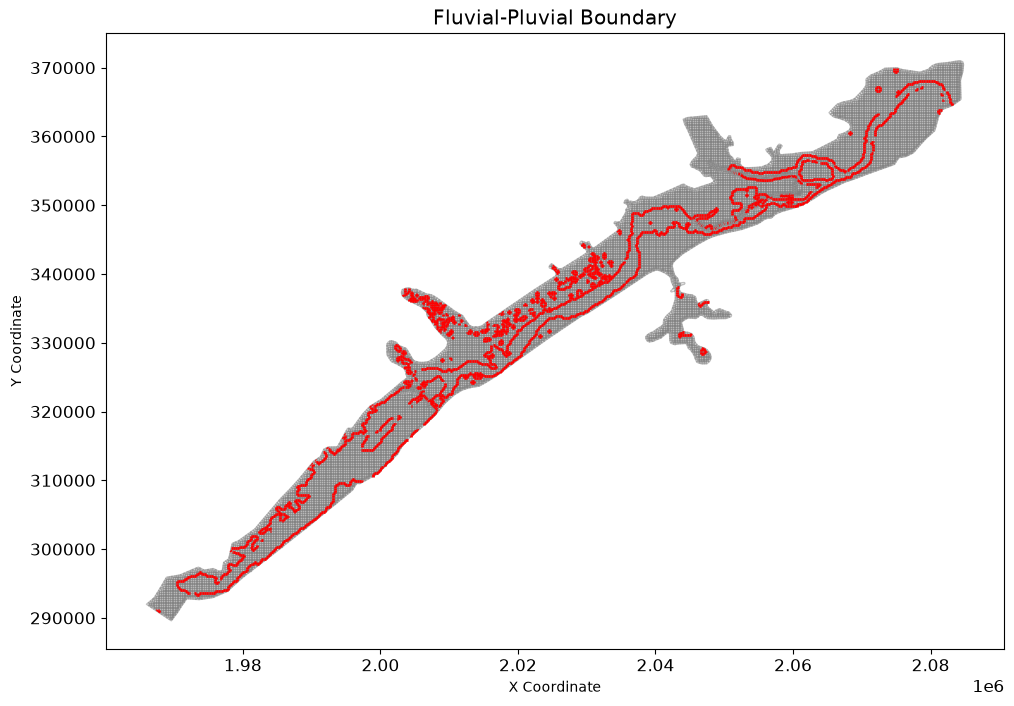

In [22]:
# Visualize the results
fig, ax = plt.subplots(figsize=(12, 8))
cell_polygons_gdf.plot(ax=ax, edgecolor='gray', facecolor='none', alpha=0.5)
boundary_gdf.plot(ax=ax, color='red', linewidth=2)
plt.title('Fluvial-Pluvial Boundary')
plt.xlabel('X Coordinate')
plt.ylabel('Y Coordinate')
plt.show()

D:\CLB-Temp\clb-t3-pr534\venv2\Lib\site-packages\geopandas\plotting.py:1408: UserWarning: The GeoSeries you are attempting to plot is empty. Nothing has been displayed.
  return plot_dataframe(data, *args, **kwargs)


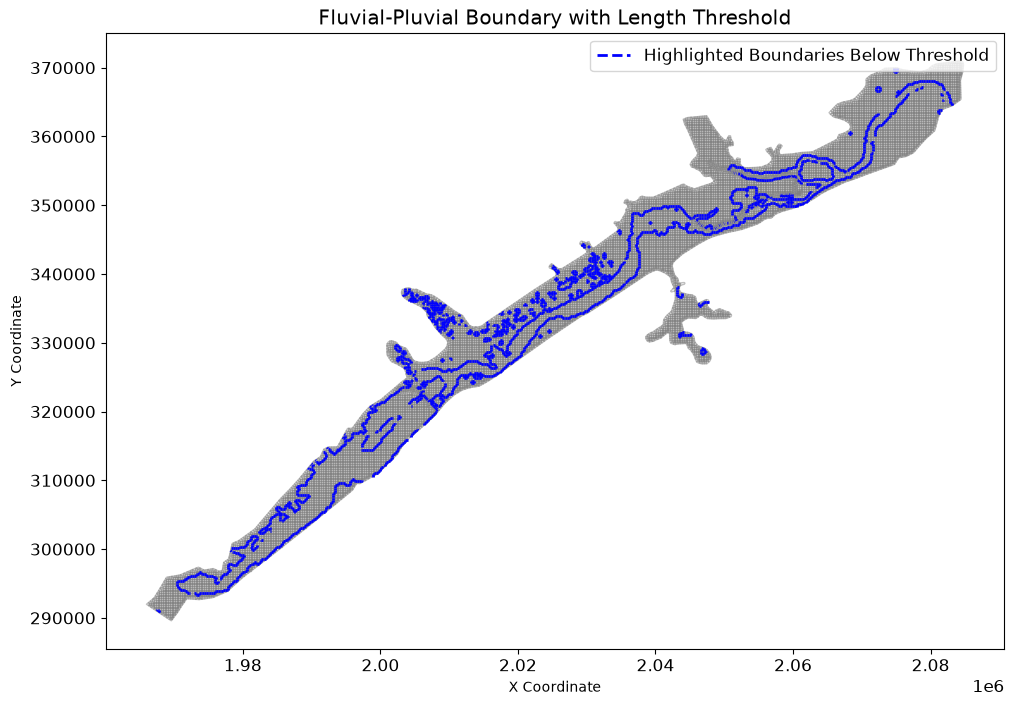

In [23]:
length_threshold = 3000 #in same units as X and Y coordinates

# Filter out boundary lines below the length threshold
filtered_boundary_gdf = boundary_gdf[boundary_lengths >= length_threshold]
highlighted_boundary_gdf = boundary_gdf[boundary_lengths < length_threshold]

# Visualize the results with highlighted boundaries below the threshold
fig, ax = plt.subplots(figsize=(12, 8))
cell_polygons_gdf.plot(ax=ax, edgecolor='gray', facecolor='none', alpha=0.5)
filtered_boundary_gdf.plot(ax=ax, color='red', linewidth=2, label='Valid Boundaries')
highlighted_boundary_gdf.plot(ax=ax, color='blue', linewidth=2, linestyle='--', label='Highlighted Boundaries Below Threshold')
plt.title('Fluvial-Pluvial Boundary with Length Threshold')
plt.xlabel('X Coordinate')
plt.ylabel('Y Coordinate')
plt.legend()
plt.show()


In [24]:
# Example usage using Optional min_line_length argument:
boundary_gdf = HdfFluvialPluvial.calculate_fluvial_pluvial_boundary(plan_hdf_path, delta_t=72, min_line_length=3000)

2026-10-15 02:41:44 - ras_commander.hdf.HdfFluvialPluvial - INFO - Fluvial/pluvial boundary: 0 line(s), delta_t=72 hr, min_line_length=3000.


2026-10-15 02:44:01 - ras_commander.hdf.HdfFluvialPluvial - INFO - Fluvial/pluvial polygons: 3 dissolved class(es), delta_t=10 hr, tolerance=1.0 hr, iterations=33, components=ambiguous: 366, fluvial: 30, pluvial: 36.


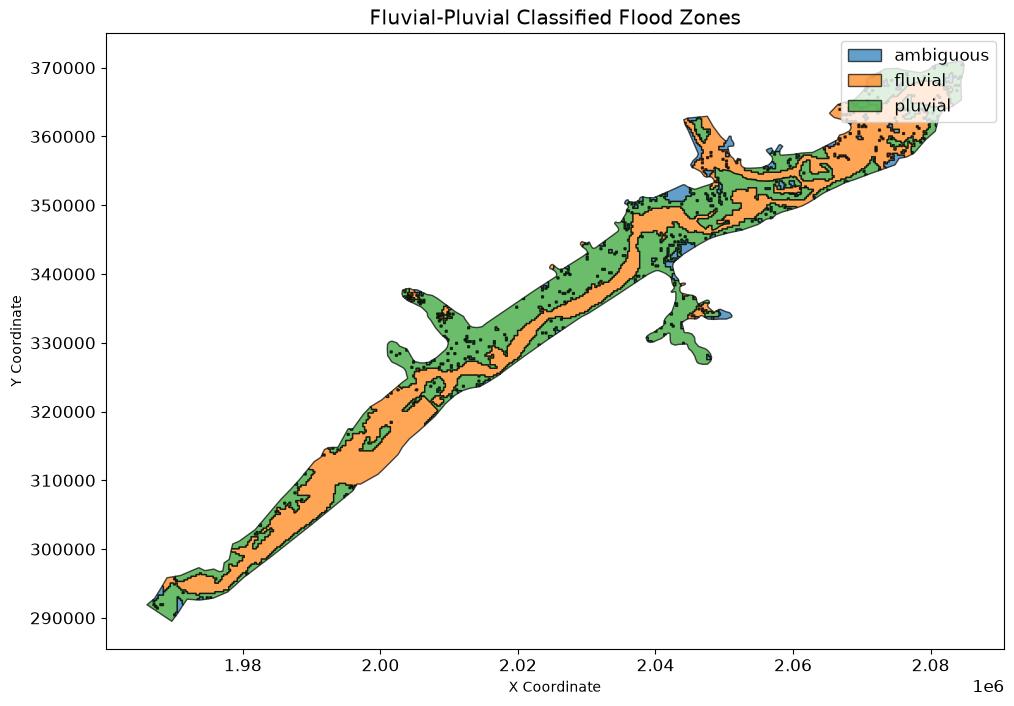

In [25]:
# To get the classified flood zones as polygons:
flood_polygons_gdf = HdfFluvialPluvial.generate_fluvial_pluvial_polygons(
    plan_hdf_path, 
    delta_t=10, 
    temporal_tolerance_hours=1.0,
    min_polygon_area_acres=1000
)

flood_polygons_gdf

# Plot the classified flood zones as polygons, colored by classification
fig, ax = plt.subplots(figsize=(12, 8))
flood_polygons_gdf.plot(
    ax=ax,
    column="classification",
    categorical=True,
    legend=True,
    edgecolor="black",
    alpha=0.7
)
plt.title("Fluvial-Pluvial Classified Flood Zones")
plt.xlabel("X Coordinate")
plt.ylabel("Y Coordinate")
plt.show()


2026-10-15 02:46:20 - ras_commander.hdf.HdfFluvialPluvial - INFO - Fluvial/pluvial polygons: 3 dissolved class(es), delta_t=12 hr, tolerance=1.0 hr, iterations=37, components=ambiguous: 350, fluvial: 34, pluvial: 31.


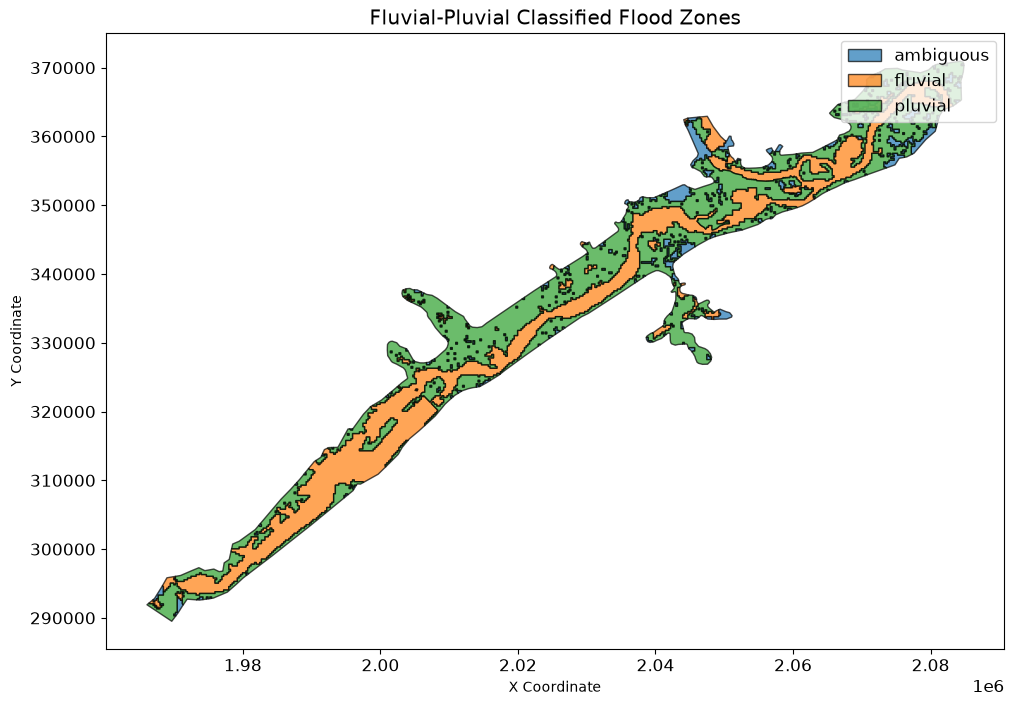

In [26]:
# To get the classified flood zones as polygons:
flood_polygons_gdf = HdfFluvialPluvial.generate_fluvial_pluvial_polygons(
    plan_hdf_path, 
    delta_t=12, 
    temporal_tolerance_hours=1.0,
    min_polygon_area_acres=200
)

flood_polygons_gdf

# Plot the classified flood zones as polygons, colored by classification
fig, ax = plt.subplots(figsize=(12, 8))
flood_polygons_gdf.plot(
    ax=ax,
    column="classification",
    categorical=True,
    legend=True,
    edgecolor="black",
    alpha=0.7
)
plt.title("Fluvial-Pluvial Classified Flood Zones")
plt.xlabel("X Coordinate")
plt.ylabel("Y Coordinate")
plt.show()


2026-10-15 02:48:40 - ras_commander.hdf.HdfFluvialPluvial - INFO - Fluvial/pluvial polygons: 3 dissolved class(es), delta_t=14 hr, tolerance=1.0 hr, iterations=37, components=ambiguous: 364, fluvial: 13, pluvial: 18.


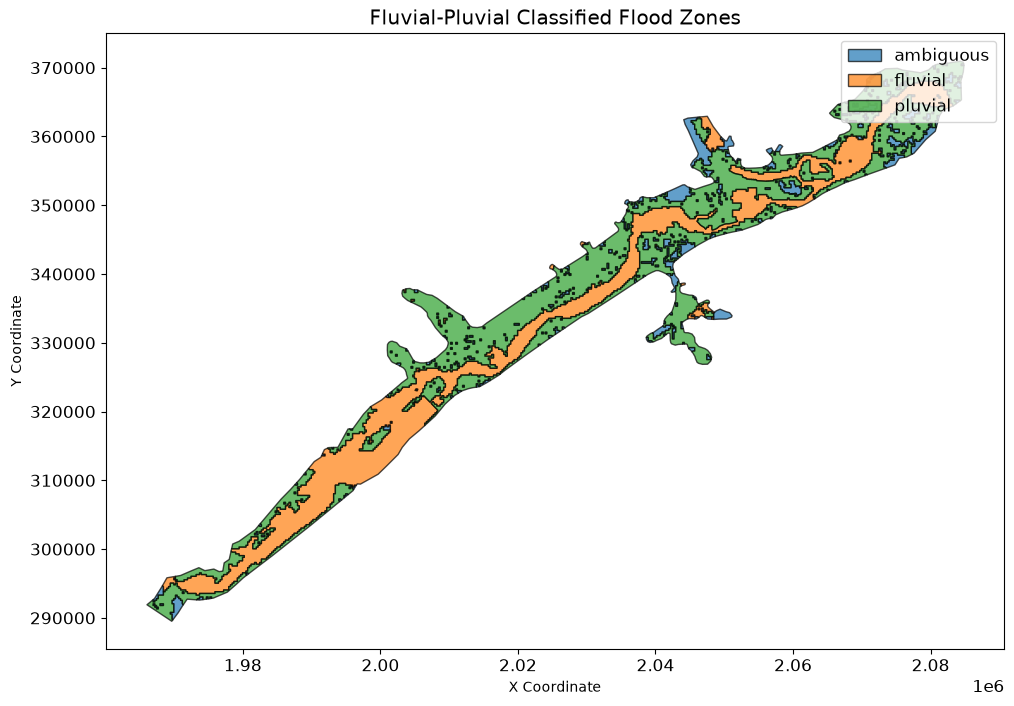

In [27]:
# To get the classified flood zones as polygons:
flood_polygons_gdf = HdfFluvialPluvial.generate_fluvial_pluvial_polygons(
    plan_hdf_path, 
    delta_t=14, 
    temporal_tolerance_hours=1.0,
    min_polygon_area_acres=1000
)

flood_polygons_gdf

# Plot the classified flood zones as polygons, colored by classification
fig, ax = plt.subplots(figsize=(12, 8))
flood_polygons_gdf.plot(
    ax=ax,
    column="classification",
    categorical=True,
    legend=True,
    edgecolor="black",
    alpha=0.7
)
plt.title("Fluvial-Pluvial Classified Flood Zones")
plt.xlabel("X Coordinate")
plt.ylabel("Y Coordinate")
plt.show()


In [28]:
flood_polygons_gdf.to_file(driver='GeoJSON', filename='flood_polygons.geojson')

2026-10-15 02:48:40 - pyogrio._io - INFO - Created 3 records


In [29]:
# Create fluvial_pluvial_boundary subfolder in project directory
output_dir = ras.project_folder / "fluvial_pluvial_boundary"
output_dir.mkdir(exist_ok=True)
print(f"Output directory created/verified at: {output_dir}")

# Save to GeoJSON in output directory
boundary_gdf.to_file(output_dir / 'fluvial_pluvial_boundary.geojson', driver='GeoJSON')

2026-10-15 02:48:40 - pyogrio._io - INFO - Created 0 records


Output directory created/verified at: D:\CLB-Temp\clb-t3-pr534\repo2\examples\example_projects\BaldEagleCrkMulti2D_14\fluvial_pluvial_boundary
